In [21]:
def neuron(inputs, weights, bias):
  shaped=zip(inputs,weights)
  total = sum(i * w for i, w in shaped) + bias
  return total

import math
def sigmoid(x):
    return 1 / (1 + math.exp(-x))

In [22]:
print(neuron([0.5, 0.8], [0.4, 0.2], 0.1))
print(sigmoid(neuron([0.5, 0.8], [0.4, 0.2], 0.1)))

0.4600000000000001
0.6130141761393355


In [23]:
def layer(inputs, layer_weights, layer_biases):
    outputs = []
    for weights, bias in zip(layer_weights, layer_biases):
        outputs.append(neuron(inputs, weights, bias))
    return outputs

In [24]:
layer_weights = [
    [0.4, 0.2],
    [0.1, 0.9],
    [0.7, 0.3],
]
layer_biases = [0.1, 0.2, 0.05]
print(layer([0.5, 0.8], layer_weights, layer_biases))

[0.4600000000000001, 0.9700000000000002, 0.64]


In [25]:
def mse_loss(predictions, targets):
    total = 0
    for p, t in zip(predictions, targets):
      total += (p - t) ** 2
    return total / len(predictions)

In [26]:
print(mse_loss([0.6, 0.9], [0.5, 1.0]))

0.009999999999999995


In [27]:
data = [(1, 2), (2, 4), (3, 6), (4, 8)]
b = 0.0

def predict(x, w, b):
    return w * x + b

def loss_for_w(w, b, data):
    predictions = []
    targets = []
    for x, target in data:
        predictions.append(predict(x, w, b))
        targets.append(target)
    return mse_loss(predictions, targets)

ws = [i * 0.1 for i in range(0, 40)]
losses = [loss_for_w(w, b, data) for w in ws]

for w, l in zip(ws, losses):
    print(round(w, 1), round(l, 3))

0.0 30.0
0.1 27.075
0.2 24.3
0.3 21.675
0.4 19.2
0.5 16.875
0.6 14.7
0.7 12.675
0.8 10.8
0.9 9.075
1.0 7.5
1.1 6.075
1.2 4.8
1.3 3.675
1.4 2.7
1.5 1.875
1.6 1.2
1.7 0.675
1.8 0.3
1.9 0.075
2.0 0.0
2.1 0.075
2.2 0.3
2.3 0.675
2.4 1.2
2.5 1.875
2.6 2.7
2.7 3.675
2.8 4.8
2.9 6.075
3.0 7.5
3.1 9.075
3.2 10.8
3.3 12.675
3.4 14.7
3.5 16.875
3.6 19.2
3.7 21.675
3.8 24.3
3.9 27.075


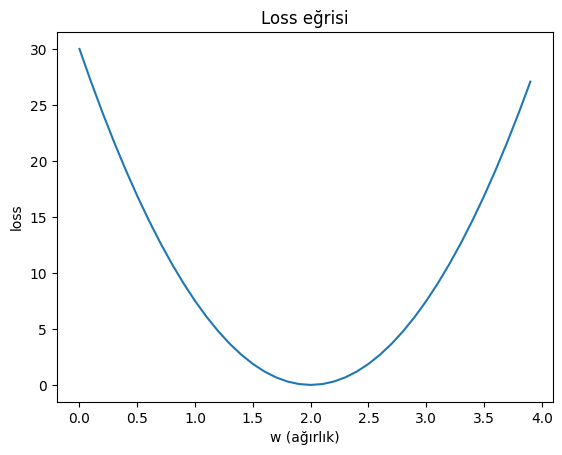

In [28]:
import matplotlib.pyplot as plt

plt.plot(ws, losses)
plt.xlabel("w (ağırlık)")
plt.ylabel("loss")
plt.title("Loss eğrisi")
plt.show()

In [29]:
data = [(1, 3.1), (2, 4.9), (3, 7.2), (4, 8.8), (5, 11.1)]

In [30]:
w = 0.0
b = 0.0
learning_rate = 0.001
h = 0.00001

for step in range(2000):
    loss_now = loss_for_w(w, b, data)
    grad_w = (loss_for_w(w + h, b, data) - loss_now) / h
    grad_b = (loss_for_w(w, b + h, data) - loss_now) / h

    w = w - learning_rate * grad_w
    b = b - learning_rate * grad_b

    if step % 200 == 0:
        print(step, "w:", round(w, 3), "b:", round(b, 3), "loss:", round(loss_now, 4))

print("Result → w:", round(w, 3), "b:", round(b, 3))

0 w: 0.05 b: 0.014 loss: 57.222
200 w: 2.093 b: 0.612 loss: 0.0595
400 w: 2.102 b: 0.645 loss: 0.0512
600 w: 2.095 b: 0.672 loss: 0.0474
800 w: 2.088 b: 0.697 loss: 0.0441
1000 w: 2.081 b: 0.72 loss: 0.0413
1200 w: 2.075 b: 0.741 loss: 0.0387
1400 w: 2.07 b: 0.762 loss: 0.0366
1600 w: 2.065 b: 0.78 loss: 0.0346
1800 w: 2.06 b: 0.798 loss: 0.033
Result → w: 2.055 b: 0.814
